# Gestión de inventario mediante Q-Learning con datos abiertos de ventas

**Asignatura:** Introducción al Machine Learning  
**Actividad:** Semana 14 — Aprendizaje por refuerzo   
**Autor:** Ferley Antonio Moreno Cruz  
**Institución:** Universidad de Cundinamarca  

## 1. Descripción del proyecto

Este proyecto desarrolla y evalúa un agente de aprendizaje por refuerzo
para tomar decisiones de reposición de inventario de un producto.

Se utilizará el conjunto de datos abierto **Online Retail**, publicado
en el UCI Machine Learning Repository por Chen (2015). Las ventas
históricas servirán como aproximación de la demanda en un entorno
simulado de inventario.

El agente aprenderá mediante Q-Learning a seleccionar cantidades de
reposición. Su desempeño se comparará con una política tradicional,
considerando costos de inventario y unidades faltantes.

## 2. Pregunta de investigación

¿Qué resultados obtiene un agente de Q-Learning frente a una política
tradicional de reposición, al decidir cuánto inventario solicitar en un
entorno simulado basado en ventas históricas?

## 3. Objetivos

### Objetivo general

Evaluar una política de reposición de inventario basada en Q-Learning
mediante su comparación con una política tradicional en un entorno
simulado construido con datos abiertos.

### Objetivos específicos

1. Preparar los datos y seleccionar un producto con suficiente historial.
2. Definir los estados, acciones, recompensas y transiciones del entorno.
3. Implementar y entrenar un agente de Q-Learning.
4. Comparar ambas políticas mediante costos, faltantes e inventario promedio.
5. Analizar los resultados y las limitaciones del experimento.

## 4. Alcance y supuestos

El estudio se limitará a un producto y a decisiones diarias de reposición.

Los datos originales contienen transacciones de venta; los niveles de
inventario, los costos y las reglas de abastecimiento se definirán como
supuestos del simulador.

Las ventas observadas se utilizarán como aproximación de la demanda.
Esta aproximación no permite identificar las compras que pudieron
perderse por falta de existencias.

La selección del producto y el ajuste de las políticas se realizarán con
el periodo de entrenamiento. Los datos de evaluación se reservarán para
la comparación final, respetando el orden temporal.

Los resultados describirán el comportamiento de las políticas bajo los
supuestos de la simulación.

## Referencia de los datos

Chen, D. (2015). *Online Retail* [Conjunto de datos].
UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33


In [1]:
%pip install -q "openpyxl>=3.1.5,<4"

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
from importlib.metadata import version

import hashlib
import json
import shutil
import sys
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from IPython.display import display

# Semilla para los procedimientos aleatorios del proyecto.
SEED = 42
rng = np.random.default_rng(SEED)

# Carpeta principal del proyecto.
PROJECT_DIR = Path.cwd() / "rl_inventario"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in (
    RAW_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

# Registrar el entorno para documentar la reproducción del trabajo.
environment = {
    "python": sys.version.split()[0],
    "packages": {
        package: version(package)
        for package in (
            "numpy",
            "pandas",
            "matplotlib",
            "requests",
            "openpyxl",
        )
    },
    "seed": SEED,
}

(RESULTS_DIR / "entorno.json").write_text(
    json.dumps(environment, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Entorno preparado.")
print(f"Carpeta del proyecto: {PROJECT_DIR}")
display(pd.Series(environment["packages"], name="Versión"))

Entorno preparado.
Carpeta del proyecto: /content/rl_inventario


,Versión
numpy,2.4.6
pandas,2.2.3
matplotlib,3.10.0
requests,2.32.4
openpyxl,3.1.5


## 5. Obtención y revisión inicial de los datos

### Fuente

Se utilizará **Online Retail**, del UCI Machine Learning Repository.
El conjunto contiene transacciones de un comercio británico entre el
1 de diciembre de 2010 y el 9 de diciembre de 2011 (Chen, 2015).

Su licencia es **Creative Commons Attribution 4.0 International
(CC BY 4.0)**, que permite compartir y adaptar los datos con atribución.

- Fuente: https://archive.ics.uci.edu/dataset/352/online+retail
- DOI: https://doi.org/10.24432/C5BW33

### Variables utilizadas

| Variable | Descripción | Utilidad |
|---|---|---|
| InvoiceNo | Identificador de la factura | Identificar cancelaciones |
| StockCode | Código del producto | Seleccionar el producto |
| Description | Descripción del producto | Interpretar el caso |
| Quantity | Cantidad registrada | Construir las ventas diarias |
| InvoiceDate | Fecha y hora de la transacción | Organizar la secuencia temporal |
| UnitPrice | Precio unitario de venta en libras esterlinas | Revisar la validez de las transacciones |

El precio de venta no equivale al costo de adquisición. Los costos del
simulador se definirán y documentarán por separado.

En esta etapa se conservarán los registros originales de las columnas
seleccionadas. La limpieza se realizará en la siguiente sección.

In [3]:
DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/"
    "352/online+retail.zip"
)

XLSX_PATH = RAW_DIR / "Online Retail.xlsx"

if XLSX_PATH.exists() and zipfile.is_zipfile(XLSX_PATH):
    print("Se utilizará el archivo descargado previamente.")

else:
    print("Descargando Online Retail desde UCI...")

    response = requests.get(
        DATASET_URL,
        timeout=(20, 180),
    )
    response.raise_for_status()

    # Extraer únicamente el Excel esperado.
    with zipfile.ZipFile(BytesIO(response.content)) as archive:
        candidates = [
            name
            for name in archive.namelist()
            if Path(name).name == "Online Retail.xlsx"
        ]

        if len(candidates) != 1:
            raise ValueError(
                "No se encontró un único archivo Online Retail.xlsx "
                "en la descarga. Revisa el contenido publicado por UCI."
            )

        temporary_path = XLSX_PATH.with_suffix(".xlsx.part")

        with archive.open(candidates[0]) as source:
            with temporary_path.open("wb") as destination:
                shutil.copyfileobj(source, destination)

        temporary_path.replace(XLSX_PATH)

    print("Descarga y extracción completadas.")

print(f"Archivo: {XLSX_PATH.name}")
print(f"Tamaño del Excel: {XLSX_PATH.stat().st_size / 1024**2:.2f} MB")

Descargando Online Retail desde UCI...
Descarga y extracción completadas.
Archivo: Online Retail.xlsx
Tamaño del Excel: 22.62 MB


In [4]:
COLUMNS = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
]

print("Leyendo el archivo Excel...")

df_raw = pd.read_excel(
    XLSX_PATH,
    engine="openpyxl",
    usecols=COLUMNS,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
    },
)

# Verificaciones básicas de la carga.
if df_raw.empty:
    raise ValueError("El archivo no contiene registros.")

if set(df_raw.columns) != set(COLUMNS):
    raise ValueError("Las columnas no coinciden con las esperadas.")

dates = pd.to_datetime(
    df_raw["InvoiceDate"],
    errors="coerce",
)

print(f"\nRegistros cargados: {len(df_raw):,}")
print(f"Columnas seleccionadas: {len(df_raw.columns)}")
print(f"Primera fecha: {dates.min()}")
print(f"Última fecha: {dates.max()}")

print("\nPrimeros registros:")
display(df_raw.head())

print("\nTipos de datos y valores ausentes:")
initial_review = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "valores_ausentes": df_raw.isna().sum(),
    "porcentaje_ausente": (
        df_raw.isna().mean() * 100
    ).round(2),
})
display(initial_review)

# Guardar la revisión inicial.
initial_review.to_csv(
    RESULTS_DIR / "revision_inicial.csv",
    index_label="variable",
)

# Registrar procedencia e identificación del archivo.
provenance = {
    "dataset": "Online Retail",
    "author": "Daqing Chen",
    "year": 2015,
    "source_url": (
        "https://archive.ics.uci.edu/dataset/352/online+retail"
    ),
    "download_url": DATASET_URL,
    "doi": "10.24432/C5BW33",
    "license": "CC BY 4.0",
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "file_sha256": hashlib.sha256(
        XLSX_PATH.read_bytes()
    ).hexdigest(),
    "rows": len(df_raw),
    "selected_columns": COLUMNS,
}

(RESULTS_DIR / "procedencia_datos.json").write_text(
    json.dumps(provenance, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("\nParte 1 completada.")

Leyendo el archivo Excel...

Registros cargados: 541,909
Columnas seleccionadas: 6
Primera fecha: 2010-12-01 08:26:00
Última fecha: 2011-12-09 12:50:00

Primeros registros:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39



Tipos de datos y valores ausentes:


,tipo,valores_ausentes,porcentaje_ausente
InvoiceNo,string,0,0.00
StockCode,string,0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
UnitPrice,float64,0,0.00



Parte 1 completada.


## 6. Preparación de los datos

Se conservarán transacciones con fecha válida, cantidades enteras
positivas y precios positivos. Se excluirán cancelaciones y registros
que no correspondan al formato de facturas de venta utilizado en este
estudio.

Chen (2015) indica que las facturas cuyo identificador comienza por
la letra C corresponden a cancelaciones.

Para delimitar el análisis a productos, se considerarán códigos de cinco
dígitos, con hasta dos letras adicionales. Esta es una regla operativa
del proyecto para excluir códigos administrativos.

Las descripciones ausentes no serán motivo de eliminación, porque el
producto puede identificarse mediante StockCode.

Las filas repetidas se contabilizarán, pero se conservarán: el archivo
no proporciona un identificador de línea que permita confirmar si
representan errores o ventas registradas por separado.

### División cronológica

Se utilizarán tres periodos consecutivos:

- **Entrenamiento: 60 % de los días.** Selección del producto y aprendizaje.
- **Validación: 20 %.** Ajuste de las políticas y sus parámetros.
- **Prueba: 20 % restante.** Comparación final.

La última fecha del archivo se excluirá como precaución ante una jornada
potencialmente incompleta, ya que el registro termina a las 12:50.

### Selección del producto

La selección utilizará exclusivamente el periodo de entrenamiento.

Se buscará un producto con ventas registradas en al menos la mitad de
los días y una media de entre 5 y 100 unidades diarias. Estos criterios
delimitan un caso manejable para la implementación individual.

Entre los candidatos se priorizará la frecuencia de ventas. En caso
de empate, se preferirá menor variabilidad relativa.

### Interpretación de los días sin ventas

Los días sin transacciones del producto se representarán con cero
unidades vendidas. Esto significa **ausencia de ventas registradas**;
no demuestra ausencia de demanda ni disponibilidad del producto.

Referencia: Chen, D. (2015). *Online Retail* [Conjunto de datos].
UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

In [5]:
# Trabajar sobre una copia para conservar df_raw.
df = df_raw.copy()

df["InvoiceNo"] = (
    df["InvoiceNo"].astype("string").str.strip().str.upper()
)
df["StockCode"] = (
    df["StockCode"].astype("string").str.strip().str.upper()
)
df["Description"] = (
    df["Description"].astype("string").str.strip()
)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)
df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

# Las reglas se calculan sobre las mismas filas originales.
rules = {
    "Fecha válida": df["InvoiceDate"].notna(),

    "Factura de venta con seis dígitos":
        df["InvoiceNo"].str.fullmatch(r"\d{6}", na=False),

    "Código de producto admitido":
        df["StockCode"].str.fullmatch(
            r"\d{5}[A-Z]{0,2}", na=False
        ),

    "Cantidad entera, finita y positiva": (
        np.isfinite(df["Quantity"])
        & df["Quantity"].gt(0)
        & df["Quantity"].mod(1).eq(0)
    ),

    "Precio finito y positivo": (
        np.isfinite(df["UnitPrice"])
        & df["UnitPrice"].gt(0)
    ),
}

audit_rows = []

# Aplicar las reglas sucesivamente para no contar una exclusión dos veces.
for rule_name, original_mask in rules.items():
    before = len(df)

    current_mask = original_mask.reindex(
        df.index
    ).fillna(False)

    df = df.loc[current_mask].copy()

    audit_rows.append({
        "regla": rule_name,
        "filas_antes": before,
        "filas_excluidas": before - len(df),
        "filas_restantes": len(df),
    })

if df.empty:
    raise ValueError("No quedaron registros después de la limpieza.")

df["Quantity"] = df["Quantity"].astype("int64")
df["date"] = df["InvoiceDate"].dt.normalize()

cleaning_audit = pd.DataFrame(audit_rows)

print("Auditoría de limpieza:")
display(cleaning_audit)

print(f"Filas repetidas conservadas: {df.duplicated().sum():,}")
print(f"Productos disponibles: {df['StockCode'].nunique():,}")

cleaning_audit.to_csv(
    RESULTS_DIR / "auditoria_limpieza.csv",
    index=False,
)

Auditoría de limpieza:


,regla,filas_antes,filas_excluidas,filas_restantes
0,Fecha válida,541909,0,541909
1,Factura de venta con seis dígitos,541909,9291,532618
2,Código de producto admitido,532618,2408,530210
3,"Cantidad entera, finita y positiva",530210,1324,528886
4,Precio finito y positivo,528886,1161,527725


Filas repetidas conservadas: 5,221
Productos disponibles: 3,791


In [6]:
# Límites del archivo original.
raw_dates = pd.to_datetime(
    df_raw["InvoiceDate"], errors="coerce"
).dropna()

start_date = raw_dates.min().normalize()
excluded_last_date = raw_dates.max().normalize()
end_date = excluded_last_date - pd.Timedelta(days=1)

calendar = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D",
)

if len(calendar) < 30:
    raise ValueError("El periodo disponible es demasiado corto.")

# Conservar solo el periodo definido.
df = df.loc[
    df["date"].between(start_date, end_date)
].copy()

# Cortes cronológicos por número de días.
n_days = len(calendar)
n_train = int(n_days * 0.60)
n_validation = int(n_days * 0.20)

train_dates = calendar[:n_train]
validation_dates = calendar[
    n_train:n_train + n_validation
]
test_dates = calendar[
    n_train + n_validation:
]

split_summary = pd.DataFrame([
    {
        "periodo": name,
        "inicio": dates.min().date().isoformat(),
        "fin": dates.max().date().isoformat(),
        "dias": len(dates),
    }
    for name, dates in (
        ("Entrenamiento", train_dates),
        ("Validación", validation_dates),
        ("Prueba", test_dates),
    )
])

print("Distribución cronológica:")
display(split_summary)

print(
    "Última fecha excluida:",
    excluded_last_date.date(),
)

split_summary.to_csv(
    RESULTS_DIR / "division_temporal.csv",
    index=False,
)


Distribución cronológica:


,periodo,inicio,fin,dias
0,Entrenamiento,2010-12-01,2011-07-11,223
1,Validación,2011-07-12,2011-09-23,74
2,Prueba,2011-09-24,2011-12-08,76


Última fecha excluida: 2011-12-09


In [7]:
train_transactions = df.loc[
    df["date"].isin(train_dates)
].copy()

# Ventas por producto y día durante entrenamiento.
product_day_sales = (
    train_transactions
    .groupby(["date", "StockCode"])["Quantity"]
    .sum()
    .unstack("StockCode")
    .reindex(train_dates)
    .fillna(0)
)

product_profile = pd.DataFrame({
    "dias_con_ventas": product_day_sales.gt(0).sum(),
    "unidades_totales": product_day_sales.sum(),
    "media_diaria": product_day_sales.mean(),
    "desviacion_diaria": product_day_sales.std(ddof=0),
    "maximo_diario": product_day_sales.max(),
})

product_profile["cobertura"] = (
    product_profile["dias_con_ventas"] / len(train_dates)
)

product_profile["variabilidad_relativa"] = (
    product_profile["desviacion_diaria"]
    / product_profile["media_diaria"]
)

# Criterios definidos antes de revisar validación o prueba.
candidates = product_profile.loc[
    product_profile["cobertura"].ge(0.50)
    & product_profile["media_diaria"].between(5, 100)
].copy()

if candidates.empty:
    raise ValueError(
        "No hay productos que cumplan los criterios. "
        "Comparte esta salida antes de modificar la selección."
    )

# Orden determinista: frecuencia, variabilidad y código.
candidates = (
    candidates
    .rename_axis("StockCode")
    .reset_index()
    .sort_values(
        ["dias_con_ventas", "variabilidad_relativa", "StockCode"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

PRODUCT_CODE = str(candidates.loc[0, "StockCode"])

# Obtener la descripción más frecuente solo en entrenamiento.
descriptions = train_transactions.loc[
    train_transactions["StockCode"].eq(PRODUCT_CODE),
    "Description",
].dropna()

descriptions = descriptions.loc[descriptions.ne("")]

PRODUCT_NAME = (
    str(descriptions.mode().iloc[0])
    if not descriptions.empty
    else "Descripción no disponible"
)

print("Producto seleccionado:")
print(f"Código: {PRODUCT_CODE}")
print(f"Descripción: {PRODUCT_NAME}")

print("\nPrimeros cinco candidatos de entrenamiento:")
display(candidates.head().round(3))

candidates.to_csv(
    RESULTS_DIR / "productos_candidatos.csv",
    index=False,
)

Producto seleccionado:
Código: 22423
Descripción: REGENCY CAKESTAND 3 TIER

Primeros cinco candidatos de entrenamiento:


,StockCode,dias_con_ventas,unidades_totales,media_diaria,desviacion_diaria,maximo_diario,cobertura,variabilidad_relativa
0,22423,174,8714.0,39.076,48.892,362.0,0.780,1.251
1,22457,173,4799.0,21.520,25.313,171.0,0.776,1.176
2,22960,172,4587.0,20.570,25.939,204.0,0.771,1.261
3,84879,171,16250.0,72.870,90.220,503.0,0.767,1.238
4,21080,170,8941.0,40.094,52.224,246.0,0.762,1.303


In [8]:
selected_transactions = df.loc[
    df["StockCode"].eq(PRODUCT_CODE)
].copy()

daily_totals = (
    selected_transactions
    .groupby("date")["Quantity"]
    .sum()
)

daily_sales = (
    daily_totals
    .reindex(calendar, fill_value=0)
    .rename("sales")
    .rename_axis("date")
    .reset_index()
)

daily_sales["sales"] = daily_sales["sales"].astype("int64")
daily_sales["weekday"] = daily_sales["date"].dt.dayofweek

daily_sales["split"] = np.select(
    [
        daily_sales["date"].isin(train_dates),
        daily_sales["date"].isin(validation_dates),
    ],
    [
        "train",
        "validation",
    ],
    default="test",
)

train_data = daily_sales.loc[
    daily_sales["split"].eq("train")
].reset_index(drop=True)

validation_data = daily_sales.loc[
    daily_sales["split"].eq("validation")
].reset_index(drop=True)

test_data = daily_sales.loc[
    daily_sales["split"].eq("test")
].reset_index(drop=True)

# Comprobar que las fechas son únicas y no se solapan.
assert daily_sales["date"].is_unique
assert train_data["date"].max() < validation_data["date"].min()
assert validation_data["date"].max() < test_data["date"].min()
assert daily_sales["sales"].ge(0).all()

for name, data in (
    ("train", train_data),
    ("validation", validation_data),
    ("test", test_data),
):
    data.to_csv(
        PROCESSED_DIR / f"ventas_diarias_{name}.csv",
        index=False,
        date_format="%Y-%m-%d",
    )

# Estadísticas para diseñar el simulador: solo entrenamiento.
train_statistics = {
    "dias": len(train_data),
    "media_diaria": float(train_data["sales"].mean()),
    "mediana_diaria": float(train_data["sales"].median()),
    "percentil_95": float(train_data["sales"].quantile(0.95)),
    "maximo_diario": int(train_data["sales"].max()),
    "dias_sin_ventas": int(train_data["sales"].eq(0).sum()),
}

data_design = {
    "product_code": PRODUCT_CODE,
    "product_name": PRODUCT_NAME,
    "selection_uses": "training_only",
    "selection_criteria": {
        "minimum_coverage": 0.50,
        "minimum_daily_mean": 5,
        "maximum_daily_mean": 100,
    },
    "excluded_last_date": excluded_last_date.date().isoformat(),
    "splits": split_summary.to_dict(orient="records"),
    "training_statistics": train_statistics,
    "zero_interpretation": "Sin ventas registradas",
    "duplicates_policy": "Conservados",
}

(RESULTS_DIR / "diseno_datos.json").write_text(
    json.dumps(data_design, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(f"Producto: {PRODUCT_CODE} — {PRODUCT_NAME}")
print("\nEstadísticas del periodo de entrenamiento:")
display(
    pd.Series(
        train_statistics,
        name="Valor",
    ).round(2)
)

print("\nPrimeros días de entrenamiento:")
display(train_data.head())

print("\nConjuntos guardados en:", PROCESSED_DIR)

Producto: 22423 — REGENCY CAKESTAND 3 TIER

Estadísticas del periodo de entrenamiento:


,Valor
dias,223.00
media_diaria,39.08
mediana_diaria,25.00
percentil_95,129.90
maximo_diario,362.00
dias_sin_ventas,49.00



Primeros días de entrenamiento:


,date,sales,weekday,split
0,2010-12-01,115,2,train
1,2010-12-02,184,3,train
2,2010-12-03,231,4,train
3,2010-12-04,0,5,train
4,2010-12-05,92,6,train



Conjuntos guardados en: /content/rl_inventario/data/processed


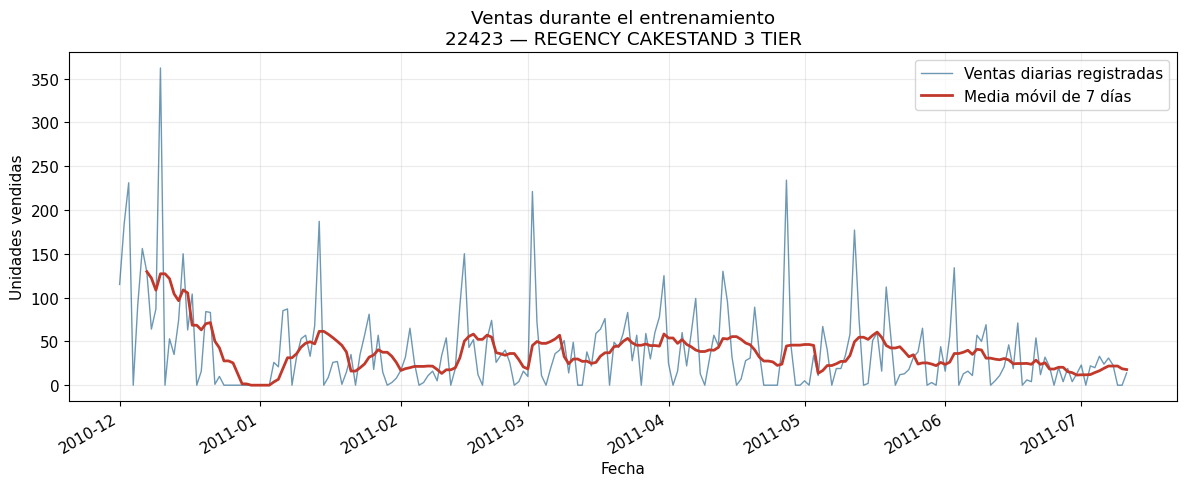

Figura guardada: ventas_entrenamiento.png
Parte 2 completada.


In [9]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    train_data["date"],
    train_data["sales"],
    color="#1f618d",
    linewidth=1,
    alpha=0.65,
    label="Ventas diarias registradas",
)

# Resumen descriptivo de los siete días terminados en cada fecha.
rolling_average = (
    train_data["sales"]
    .rolling(window=7, min_periods=7)
    .mean()
)

ax.plot(
    train_data["date"],
    rolling_average,
    color="#c0392b",
    linewidth=2,
    label="Media móvil de 7 días",
)

ax.set_title(
    f"Ventas durante el entrenamiento\n"
    f"{PRODUCT_CODE} — {PRODUCT_NAME}"
)
ax.set_xlabel("Fecha")
ax.set_ylabel("Unidades vendidas")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

figure_path = FIGURES_DIR / "ventas_entrenamiento.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figura guardada:", figure_path.name)
print("Parte 2 completada.")

## 7. Diseño del entorno de aprendizaje por refuerzo

El agente tomará una decisión de reposición al inicio de cada día.
La representación del problema mediante estados, acciones y recompensas
sigue el marco de Sutton y Barto (2018).

### Componentes

| Elemento | Definición en el proyecto |
|---|---|
| Agente | Responsable automático de la reposición |
| Entorno | Simulador diario del inventario del producto seleccionado |
| Estado observado | Inventario disponible, día de la semana y nivel de ventas recientes |
| Acciones | Cinco cantidades posibles de pedido, incluida la opción de no pedir |
| Recompensa | Valor negativo del costo operativo diario |
| Episodio | Una secuencia de días del periodo utilizado |

El nivel de ventas recientes se calculará con los siete días anteriores
disponibles. Las ventas del día actual solo se revelarán después de
ejecutar la acción.

El estado es una representación aproximada: resumir el historial no
garantiza capturar todos los factores que influyen en las ventas.

### Supuestos operativos

1. Los pedidos llegan inmediatamente al comienzo del día.
2. La capacidad del inventario es limitada.
3. Si un pedido supera el espacio disponible, solo se recibe la cantidad
   que cabe en el almacén.
4. Las unidades que no pueden atenderse se consideran faltantes perdidos:
   no se acumulan como pedidos pendientes.
5. Cada episodio comienza con inventario cero, salvo que se indique
   expresamente otra condición.
6. Las cantidades vendidas en los datos originales se utilizan como
   demanda de referencia del simulador.
7. Los costos son supuestos académicos expresados en unidades monetarias
   simuladas; no representan costos reales del comercio.

### Secuencia de cada día

1. Observar el estado.
2. Seleccionar una cantidad de pedido.
3. Recibir las unidades permitidas por la capacidad.
4. Revelar la demanda del día.
5. Calcular unidades atendidas, faltantes e inventario final.
6. Calcular el costo y devolver la recompensa.

### Función de recompensa

El costo operativo diario será:

$$
C_t =
K\,\mathbb{1}(q_t > 0)
+ h I_t^{final}
+ p F_t
$$

Donde:

- $K$: costo fijo de realizar un pedido.
- $q_t$: cantidad efectivamente recibida.
- $h$: costo por unidad almacenada al final del día.
- $I_t^{final}$: inventario final.
- $p$: penalización por unidad faltante.
- $F_t$: unidades no atendidas.

La recompensa será:

$$
r_t = -C_t
$$

Se considerarán costos de pedido, almacenamiento y faltantes.
El costo de adquisición y los ingresos por ventas quedan fuera del
objetivo de este experimento.

### Referencia teórica

Sutton, R. S., & Barto, A. G. (2018).
*Reinforcement learning: An introduction* (2nd ed.). MIT Press.
https://web.stanford.edu/class/psych209/Readings/SuttonBartoIPRLBook2ndEd.pdf

In [10]:
# Estadísticas calculadas únicamente con entrenamiento.
mean_train = float(train_data["sales"].mean())
p95_train = float(train_data["sales"].quantile(0.95))

# Tamaño básico de pedido: aproximadamente 1/4 de la media diaria.
ORDER_UNIT = max(1, int(np.ceil(mean_train / 4)))

# Cinco acciones posibles.
ORDER_QUANTITIES = [
    0,
    ORDER_UNIT,
    2 * ORDER_UNIT,
    4 * ORDER_UNIT,
    8 * ORDER_UNIT,
]

# Capacidad basada en la media y el percentil 95 de entrenamiento.
capacity_reference = max(
    3 * mean_train,
    2 * p95_train,
)

CAPACITY = int(
    np.ceil(capacity_reference / ORDER_UNIT) * ORDER_UNIT
)

# Media reciente calculada con días anteriores, excluyendo el actual.
lagged_mean = (
    train_data["sales"]
    .shift(1)
    .rolling(window=7, min_periods=1)
    .mean()
    .dropna()
)

# Umbrales para representar hasta tres niveles de ventas recientes.
DEMAND_BINS = np.unique(
    lagged_mean.quantile([1 / 3, 2 / 3]).to_numpy()
).tolist()

ENV_CONFIG = {
    "capacity": CAPACITY,
    "order_quantities": ORDER_QUANTITIES,
    "fixed_order_cost": 2.0,
    "holding_cost": 0.10,
    "shortage_cost": 5.0,
    "history_window": 7,
    "demand_bins": DEMAND_BINS,
    "prior_mean": mean_train,
}

(RESULTS_DIR / "configuracion_entorno.json").write_text(
    json.dumps(ENV_CONFIG, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(f"Producto: {PRODUCT_CODE} — {PRODUCT_NAME}")
print(f"Media diaria de entrenamiento: {mean_train:.2f}")
print(f"Percentil 95: {p95_train:.2f}")
print(f"Capacidad: {CAPACITY} unidades")
print(f"Cantidades de pedido: {ORDER_QUANTITIES}")
print(f"Umbrales de ventas recientes: {np.round(DEMAND_BINS, 2)}")

print("\nCostos académicos asumidos:")
print("Pedido: 2.00 por pedido efectivamente recibido")
print("Almacenamiento: 0.10 por unidad al final del día")
print("Faltantes: 5.00 por unidad no atendida")

Producto: 22423 — REGENCY CAKESTAND 3 TIER
Media diaria de entrenamiento: 39.08
Percentil 95: 129.90
Capacidad: 260 unidades
Cantidades de pedido: [0, 10, 20, 40, 80]
Umbrales de ventas recientes: [26.48 45.48]

Costos académicos asumidos:
Pedido: 2.00 por pedido efectivamente recibido
Almacenamiento: 0.10 por unidad al final del día
Faltantes: 5.00 por unidad no atendida


In [15]:
class InventoryEnv:
    """Simulador diario con reposición inmediata y faltantes perdidos."""

    def __init__(self, data, config, initial_history=None):
        self.data = data[["date", "sales"]].copy().reset_index(drop=True)
        self.data["date"] = pd.to_datetime(self.data["date"])
        demand = self.data["sales"].to_numpy(dtype=float)

        if len(self.data) == 0:
            raise ValueError("El periodo está vacío.")

        if self.data["date"].isna().any():
            raise ValueError("Hay fechas no válidas.")

        if not self.data["date"].diff().dropna().eq(
            pd.Timedelta(days=1)
        ).all():
            raise ValueError("Las fechas deben ser diarias y consecutivas.")

        if not np.isfinite(demand).all() or (demand < 0).any():
            raise ValueError("La demanda debe ser finita y no negativa.")

        if not np.equal(demand, np.floor(demand)).all():
            raise ValueError(
                "La demanda debe estar expresada en unidades enteras."
            )

        self.config = dict(config)
        self.capacity = int(config["capacity"])
        self.actions = np.asarray(config["order_quantities"], dtype=int)
        self.bins = np.asarray(config["demand_bins"], dtype=float)
        self.window = int(config["history_window"])

        self.demands = demand.astype(int)
        self.dates = self.data["date"].to_numpy()
        self.weekdays = (
            self.data["date"].dt.dayofweek.to_numpy(dtype=int)
        )

        self.prefix_history = (
            list(initial_history)
            if initial_history is not None
            else []
        )

        self.n_actions = len(self.actions)
        self.state_shape = (
            self.capacity + 1,
            7,
            len(self.bins) + 1,
        )

        self.reset()

    def reset(self, start_idx=0, end_idx=None, initial_inventory=0):
        end_idx = len(self.data) if end_idx is None else int(end_idx)

        if not 0 <= start_idx < end_idx <= len(self.data):
            raise ValueError("Los límites del episodio no son válidos.")

        if not 0 <= initial_inventory <= self.capacity:
            raise ValueError("El inventario inicial excede los límites.")

        if int(initial_inventory) != initial_inventory:
            raise ValueError("El inventario inicial debe ser entero.")

        self.t = int(start_idx)
        self.end_idx = end_idx
        self.inventory = int(initial_inventory)

        # Solo historial anterior al comienzo del episodio.
        self.history = (
            self.prefix_history + self.demands[:self.t].tolist()
        )[-self.window:]

        self.done = False
        return self._state()

    def _state(self):
        recent_mean = (
            float(np.mean(self.history))
            if self.history
            else float(self.config["prior_mean"])
        )

        demand_level = int(
            np.digitize(recent_mean, self.bins)
        )

        return (
            self.inventory,
            int(self.weekdays[self.t]),
            demand_level,
        )

    def step(self, action_idx):
        if self.done:
            raise RuntimeError("El episodio terminó. Ejecuta reset().")

        if not isinstance(action_idx, (int, np.integer)):
            raise ValueError("La acción debe ser un índice entero.")

        if not 0 <= action_idx < self.n_actions:
            raise ValueError("Índice de acción no válido.")

        inventory_start = self.inventory
        requested_order = int(self.actions[action_idx])

        # El pedido recibido respeta la capacidad.
        order_received = min(
            requested_order,
            self.capacity - inventory_start,
        )

        available = inventory_start + order_received

        # La demanda se revela después de seleccionar la acción.
        demand = int(self.demands[self.t])

        served_units = min(available, demand)
        lost_units = demand - served_units
        self.inventory = available - served_units

        order_cost = float(
            self.config["fixed_order_cost"]
            if order_received > 0
            else 0
        )

        holding_cost = (
            self.config["holding_cost"] * self.inventory
        )

        shortage_cost = (
            self.config["shortage_cost"] * lost_units
        )

        total_cost = (
            order_cost + holding_cost + shortage_cost
        )

        info = {
            "date": self.dates[self.t],
            "inventory_start": inventory_start,
            "requested_order": requested_order,
            "order_received": order_received,
            "demand": demand,
            "served_units": served_units,
            "lost_units": lost_units,
            "inventory_end": self.inventory,
            "order_cost": order_cost,
            "holding_cost": holding_cost,
            "shortage_cost": shortage_cost,
            "total_cost": total_cost,
        }

        # Actualizar el historial para la decisión del siguiente día.
        self.history = (
            self.history + [demand]
        )[-self.window:]

        self.t += 1
        self.done = self.t >= self.end_idx

        next_state = (
            None if self.done else self._state()
        )

        return next_state, -total_cost, self.done, info

In [16]:
small_data = pd.DataFrame({
    "date": pd.date_range(
        "2024-01-01", periods=3, freq="D"
    ),
    "sales": [4, 8, 0],
})

test_config = {
    "capacity": 10,
    "order_quantities": [0, 5, 10],
    "fixed_order_cost": 2.0,
    "holding_cost": 0.10,
    "shortage_cost": 5.0,
    "history_window": 7,
    "demand_bins": [3.0, 7.0],
    "prior_mean": 4.0,
}

check_env = InventoryEnv(small_data, test_config)
state0 = check_env.reset()

# Día 1: pedir 5, atender 4 y conservar 1.
_, reward1, _, info1 = check_env.step(1)

assert info1["inventory_end"] == 1
assert info1["served_units"] == 4
assert info1["lost_units"] == 0
assert np.isclose(reward1, -2.10)

# Día 2: no pedir; atender 1 y perder 7.
_, reward2, _, info2 = check_env.step(0)

assert info2["served_units"] == 1
assert info2["lost_units"] == 7
assert np.isclose(reward2, -35.0)

# Día 3: sin demanda y sin pedido.
next_state, reward3, done3, _ = check_env.step(0)

assert done3 and next_state is None
assert np.isclose(
    reward1 + reward2 + reward3,
    -37.10,
)

# Capacidad: con 9 unidades, solo puede recibir 1 adicional.
check_env.reset(initial_inventory=9)
_, _, _, clipped_info = check_env.step(2)

assert clipped_info["order_received"] == 1
assert clipped_info["inventory_end"] == 6

# Cambiar la demanda actual y futura no debe cambiar el estado inicial.
changed_data = small_data.copy()
changed_data["sales"] = [40, 80, 100]

other_env = InventoryEnv(
    changed_data,
    test_config,
)

assert state0 == other_env.reset()

print("Pruebas superadas:")
print("✓ Balance del inventario")
print("✓ Cálculo de costos y recompensas")
print("✓ Límite de capacidad")
print("✓ Finalización del episodio")
print("✓ Estado inicial sin anticipación de ventas")

Pruebas superadas:
✓ Balance del inventario
✓ Cálculo de costos y recompensas
✓ Límite de capacidad
✓ Finalización del episodio
✓ Estado inicial sin anticipación de ventas


In [17]:
demo_env = InventoryEnv(
    train_data,
    ENV_CONFIG,
)

state = demo_env.reset(
    end_idx=min(14, len(train_data))
)

demo_rows = []
done = False

# Regla ilustrativa: intentar disponer de dos días de ventas medias.
target_inventory = min(
    CAPACITY,
    int(np.ceil(2 * mean_train)),
)

while not done:
    inventory_now = state[0]

    desired_order = max(
        0,
        target_inventory - inventory_now,
    )

    # Seleccionar la cantidad permitida más cercana.
    action_idx = int(
        np.argmin(
            np.abs(demo_env.actions - desired_order)
        )
    )

    state, reward, done, info = demo_env.step(
        action_idx
    )

    demo_rows.append({
        **info,
        "reward": reward,
    })

demo_results = pd.DataFrame(demo_rows)

print("Demostración del simulador:")
display(
    demo_results[[
        "date",
        "inventory_start",
        "order_received",
        "demand",
        "served_units",
        "lost_units",
        "inventory_end",
        "total_cost",
    ]].round(2)
)

demo_results.to_csv(
    RESULTS_DIR / "demostracion_entorno.csv",
    index=False,
    date_format="%Y-%m-%d",
)

print("\nDimensiones del estado:", demo_env.state_shape)
print("Número de acciones:", demo_env.n_actions)
print("Parte 3 completada.")

Demostración del simulador:


,date,inventory_start,order_received,demand,served_units,lost_units,inventory_end,total_cost
0,2010-12-01,0,80,115,80,35,0,177.0
1,2010-12-02,0,80,184,80,104,0,522.0
2,2010-12-03,0,80,231,80,151,0,757.0
3,2010-12-04,0,80,0,0,0,80,10.0
4,2010-12-05,80,0,92,80,12,0,60.0
5,2010-12-06,0,80,156,80,76,0,382.0
6,2010-12-07,0,80,129,80,49,0,247.0
7,2010-12-08,0,80,64,64,0,16,3.6
8,2010-12-09,16,80,87,87,0,9,2.9
9,2010-12-10,9,80,362,89,273,0,1367.0



Dimensiones del estado: (261, 7, 3)
Número de acciones: 5
Parte 3 completada.


## 8. Implementación de Q-Learning y evaluación

Q-Learning actualiza el valor de una acción mediante:

$$
Q(s,a) \leftarrow Q(s,a) +
\alpha \left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]
$$

En el último paso del episodio se utiliza únicamente la recompensa
inmediata, sin agregar el valor de un estado posterior
(Sutton & Barto, 2018).

Para reducir el número de estados, el inventario se agrupa en intervalos
del tamaño básico de pedido. Se conservan el día de la semana y el nivel
de ventas recientes.

Se realizarán tres entrenamientos con semillas diferentes. Cada uno
utilizará 2.500 episodios de 28 días, seleccionados exclusivamente
del periodo de entrenamiento, con inventarios iniciales variables.

La exploración disminuye linealmente de 1,00 a 0,05.
Se utilizarán alpha = 0,15 y gamma = 0,95.

Cada 500 episodios se evaluará la política en validación. Se conservará
la mejor versión de cada semilla y se seleccionará el modelo final
por su costo de validación, antes de consultar el periodo de prueba.

La política tradicional seguirá una regla (s, S): solicitar reposición
cuando el inventario alcance un umbral s, intentando aproximarse a un
nivel S mediante las mismas cantidades de pedido permitidas al agente.

Los parámetros de la política tradicional también se seleccionarán
mediante validación. En prueba, ambas políticas comenzarán con
inventario cero y enfrentarán la misma secuencia de demanda.

Se compararán costo total, faltantes, inventario promedio, porcentaje
de unidades atendidas y número de pedidos. Las otras dos semillas
también se reportarán para mostrar la variabilidad observada.

Referencia: Sutton, R. S., & Barto, A. G. (2018).
*Reinforcement learning: An introduction* (2nd ed.). MIT Press.

Regla tradicional seleccionada: {'s': 39, 'S': 118, 'costo_total': 2828.5, 'faltantes': 476, 'inventario_promedio': 53.851351351351354, 'nivel_servicio_pct': 80.2653399668325, 'numero_pedidos': 25}
Entrenando Q-Learning: semilla 42...
  Costo de validación: 1705.00
Entrenando Q-Learning: semilla 43...
  Costo de validación: 1726.10
Entrenando Q-Learning: semilla 44...
  Costo de validación: 1938.30


,politica,seed,costo_total,faltantes,inventario_promedio,nivel_servicio_pct,numero_pedidos
0,Tradicional,-1,2333.7,383,47.20,86.00,30
1,Q-Learning 42,42,1701.5,178,93.09,93.49,52
2,Q-Learning 43,43,1922.7,132,149.30,95.17,64
3,Q-Learning 44,44,1091.8,27,109.84,99.01,61


Semilla elegida solo por validación: 42


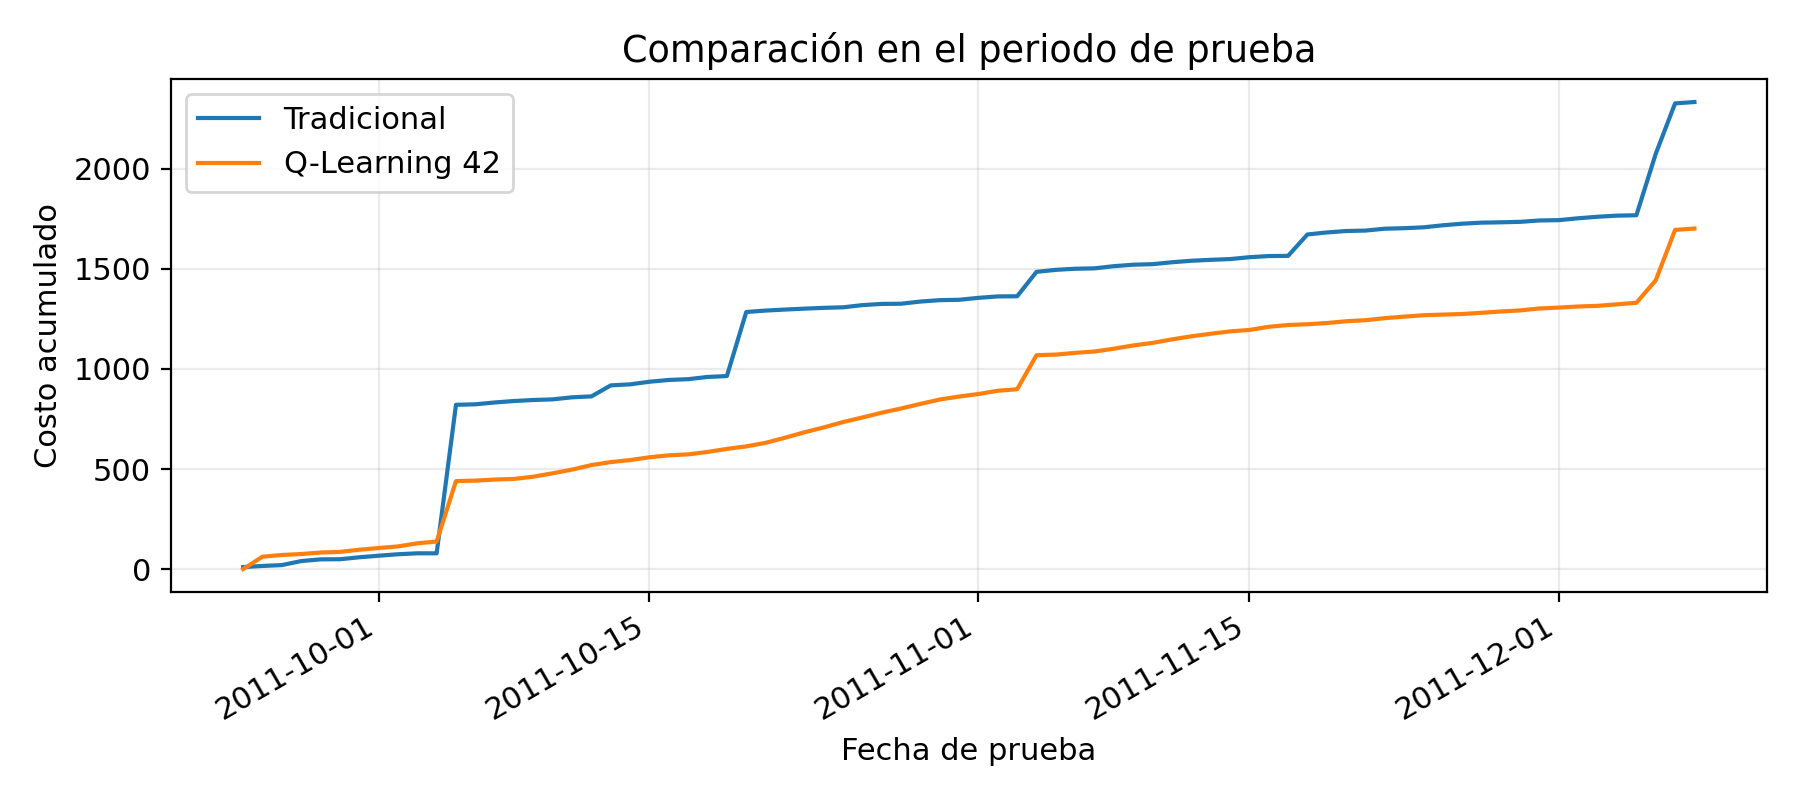

In [18]:
SEEDS = [42, 43, 44]
EPISODES = 2500
HORIZON = 28
ALPHA = 0.15
GAMMA = 0.95
CHECK_EVERY = 500


def q_index(state):
    return (
        int(state[0]) // ORDER_UNIT,
        int(state[1]),
        int(state[2]),
    )


def traditional_action(state, env, s, S):
    desired = max(0, S - state[0]) if state[0] <= s else 0
    return int(np.argmin(np.abs(env.actions - desired)))


def evaluate_policy(data, policy, history=None):
    env = InventoryEnv(
        data, ENV_CONFIG, initial_history=history
    )
    state = env.reset(initial_inventory=0)
    rows = []
    done = False

    while not done:
        action = int(policy(state, env))
        state, reward, done, info = env.step(action)
        rows.append({**info, "reward": reward})

    log = pd.DataFrame(rows)
    demand = int(log["demand"].sum())
    lost = int(log["lost_units"].sum())

    metrics = {
        "costo_total": float(log["total_cost"].sum()),
        "faltantes": lost,
        "inventario_promedio": float(
            log["inventory_end"].mean()
        ),
        "nivel_servicio_pct": (
            100 * (1 - lost / demand) if demand else 100.0
        ),
        "numero_pedidos": int(
            log["order_received"].gt(0).sum()
        ),
    }
    return metrics, log


def greedy_action(q, state):
    values = q[q_index(state)]
    # Desempate determinista: mayor pedido entre acciones empatadas.
    return int(
        np.flatnonzero(values == values.max())[-1]
    )


def train_agent(seed):
    random = np.random.default_rng(seed)
    env = InventoryEnv(train_data, ENV_CONFIG)

    shape = (
        ENV_CONFIG["capacity"] // ORDER_UNIT + 1,
        7,
        len(ENV_CONFIG["demand_bins"]) + 1,
        env.n_actions,
    )
    q = np.zeros(shape, dtype=float)

    best_cost = float("inf")
    best_q = None
    best_episode = 0
    trace = []

    horizon = min(HORIZON, len(train_data))
    history = train_data["sales"].tail(7).tolist()

    for episode in range(1, EPISODES + 1):
        start = int(
            random.integers(
                0, len(train_data) - horizon + 1
            )
        )
        initial = int(
            random.integers(
                0, ENV_CONFIG["capacity"] + 1
            )
        )

        state = env.reset(
            start, start + horizon, initial
        )
        epsilon = max(
            0.05, 1 - 0.95 * episode / EPISODES
        )
        done = False

        while not done:
            index = q_index(state)

            if random.random() < epsilon:
                action = int(
                    random.integers(env.n_actions)
                )
            else:
                values = q[index]
                action = int(
                    random.choice(
                        np.flatnonzero(
                            values == values.max()
                        )
                    )
                )

            next_state, reward, done, _ = env.step(action)

            target = reward
            if not done:
                target += GAMMA * float(
                    q[q_index(next_state)].max()
                )

            q[index + (action,)] += ALPHA * (
                target - q[index + (action,)]
            )
            state = next_state

        if (
            episode % CHECK_EVERY == 0
            or episode == EPISODES
        ):
            metrics, _ = evaluate_policy(
                validation_data,
                lambda state, env: greedy_action(q, state),
                history,
            )
            cost = metrics["costo_total"]

            trace.append({
                "seed": seed,
                "episode": episode,
                "validation_cost": cost,
            })

            if cost < best_cost:
                best_cost = cost
                best_q = q.copy()
                best_episode = episode

    return {
        "seed": seed,
        "q": best_q,
        "validation_cost": best_cost,
        "selected_episode": best_episode,
        "trace": trace,
    }


def run_experiment():
    history_val = train_data["sales"].tail(7).tolist()
    history_test = validation_data["sales"].tail(7).tolist()

    mean = float(train_data["sales"].mean())
    capacity = int(ENV_CONFIG["capacity"])
    baseline_candidates = []

    # Ajuste de la regla tradicional usando solo validación.
    for factor_s in (0.25, 0.5, 1.0):
        for factor_S in (1.0, 1.5, 2.0, 3.0):
            s = int(round(factor_s * mean))
            S = min(
                capacity,
                int(np.ceil(factor_S * mean)),
            )

            if S <= s:
                continue

            metrics, _ = evaluate_policy(
                validation_data,
                lambda state, env, s=s, S=S:
                    traditional_action(state, env, s, S),
                history_val,
            )

            baseline_candidates.append({
                "s": s, "S": S, **metrics
            })

    pd.DataFrame(baseline_candidates).to_csv(
        RESULTS_DIR / "validacion_tradicional.csv",
        index=False,
    )

    best_baseline = min(
        baseline_candidates,
        key=lambda row: row["costo_total"],
    )
    print(
        "Regla tradicional seleccionada:",
        best_baseline,
        flush=True,
    )

    models = []

    for seed in SEEDS:
        print(
            f"Entrenando Q-Learning: semilla {seed}...",
            flush=True,
        )
        model = train_agent(seed)
        models.append(model)

        print(
            "  Costo de validación: "
            f"{model['validation_cost']:.2f}",
            flush=True,
        )

    # Selección final antes de consultar prueba.
    selected = min(
        models,
        key=lambda model: model["validation_cost"],
    )

    rows = []
    logs = {}

    metrics, log = evaluate_policy(
        test_data,
        lambda state, env: traditional_action(
            state, env,
            best_baseline["s"],
            best_baseline["S"],
        ),
        history_test,
    )

    rows.append({
        "politica": "Tradicional",
        "seed": -1,
        **metrics,
    })
    logs["Tradicional"] = log

    # Evaluación final de las tres versiones ya seleccionadas.
    for model in models:
        metrics, log = evaluate_policy(
            test_data,
            lambda state, env, q=model["q"]:
                greedy_action(q, state),
            history_test,
        )

        label = f"Q-Learning {model['seed']}"
        rows.append({
            "politica": label,
            "seed": model["seed"],
            **metrics,
        })
        logs[label] = log

        np.save(
            RESULTS_DIR / f"q_seed_{model['seed']}.npy",
            model["q"],
        )

    comparison = pd.DataFrame(rows)
    comparison.to_csv(
        RESULTS_DIR / "comparacion_prueba.csv",
        index=False,
    )

    trace = pd.DataFrame([
        row
        for model in models
        for row in model["trace"]
    ])
    trace.to_csv(
        RESULTS_DIR / "curva_validacion.csv",
        index=False,
    )

    for label, log in logs.items():
        log.to_csv(
            RESULTS_DIR
            / (label.replace(" ", "_") + "_prueba.csv"),
            index=False,
            date_format="%Y-%m-%d",
        )

    selected_label = f"Q-Learning {selected['seed']}"

    selection = {
        "selected_seed": int(selected["seed"]),
        "selected_episode": int(
            selected["selected_episode"]
        ),
        "baseline_s": int(best_baseline["s"]),
        "baseline_S": int(best_baseline["S"]),
        "episodes": EPISODES,
        "horizon": HORIZON,
        "alpha": ALPHA,
        "gamma": GAMMA,
        "seeds": SEEDS,
        "inventory_bin_width": ORDER_UNIT,
        "epsilon": "Descenso lineal de 1.0 a 0.05",
        "selection_criterion":
            "Costo mínimo de validación",
        "greedy_ties":
            "Mayor pedido entre acciones empatadas",
    }

    (RESULTS_DIR / "seleccion_modelo.json").write_text(
        json.dumps(
            selection, indent=2, ensure_ascii=False
        ),
        encoding="utf-8",
    )

    fig, ax = plt.subplots(figsize=(9, 4))

    for seed, group in trace.groupby("seed"):
        ax.plot(
            group["episode"],
            group["validation_cost"],
            marker="o",
            label=f"Semilla {seed}",
        )

    ax.set(
        xlabel="Episodio",
        ylabel="Costo de validación",
        title="Evaluación durante el entrenamiento",
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "aprendizaje.png",
        dpi=200,
    )
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(9, 4))

    for label in ("Tradicional", selected_label):
        log = logs[label]
        ax.plot(
            pd.to_datetime(log["date"]),
            log["total_cost"].cumsum(),
            label=label,
        )

    ax.set(
        xlabel="Fecha de prueba",
        ylabel="Costo acumulado",
        title="Comparación en el periodo de prueba",
    )
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "comparacion.png",
        dpi=200,
    )
    plt.close(fig)

    return comparison, selection, trace


comparison, selection, learning_trace = run_experiment()

display(comparison.round(2))
print(
    "Semilla elegida solo por validación:",
    selection["selected_seed"],
)

from IPython.display import Image as DisplayImage

display(DisplayImage(
    filename=str(FIGURES_DIR / "comparacion.png")
))

In [22]:
%pip install -q python-docx

from pathlib import Path
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from google.colab import files

import reportlab.platypus as rl
from reportlab.platypus import (
    Paragraph as RLParagraph,
    Table as RLTable,
    Image as RLImage,
    PageBreak as RLPageBreak,
)

if "build_report" not in globals():
    raise RuntimeError(
        "Ejecuta primero la celda 20 para disponer del informe."
    )

# Recuperar el contenido del informe calculado.
captured = {}


class CaptureDocument:
    def __init__(self, *args, **kwargs):
        pass

    def build(self, story, **kwargs):
        captured["story"] = list(story)


original_document = rl.SimpleDocTemplate

try:
    rl.SimpleDocTemplate = CaptureDocument
    build_report(
        PROJECT_DIR,
        "https://github.com/AntonyMorenoCod/"
        "rl-inventario-qlearning",
    )
finally:
    rl.SimpleDocTemplate = original_document

# Crear el documento Word.
doc = Document()
section = doc.sections[0]

section.page_width = Inches(8.5)
section.page_height = Inches(11)

section.top_margin = Inches(1)
section.bottom_margin = Inches(1)
section.left_margin = Inches(1)
section.right_margin = Inches(1)

normal = doc.styles["Normal"]
normal.font.name = "Times New Roman"
normal.font.size = Pt(12)
normal.font.color.rgb = RGBColor(0, 0, 0)

normal.paragraph_format.line_spacing = 2
normal.paragraph_format.space_before = Pt(0)
normal.paragraph_format.space_after = Pt(0)
normal.paragraph_format.first_line_indent = Inches(0.5)

for name in ("Title", "Heading 1"):
    style = doc.styles[name]
    style.font.name = "Times New Roman"
    style.font.size = Pt(12)
    style.font.bold = True
    style.font.color.rgb = RGBColor(0, 0, 0)
    style.paragraph_format.first_line_indent = Inches(0)
    style.paragraph_format.line_spacing = 2

# Número de página en la esquina superior derecha.
header = section.header.paragraphs[0]
header.alignment = WD_ALIGN_PARAGRAPH.RIGHT
header.paragraph_format.first_line_indent = Inches(0)

field = OxmlElement("w:fldSimple")
field.set(qn("w:instr"), "PAGE")
header._p.append(field)

title_written = False
cover = True

for item in captured["story"]:

    if isinstance(item, RLPageBreak):
        doc.add_page_break()
        cover = False
        continue

    if isinstance(item, RLParagraph):
        style_name = item.style.name
        paragraph = doc.add_paragraph()

        if style_name == "Heading":
            if not title_written:
                paragraph.style = doc.styles["Title"]
                paragraph.paragraph_format.space_before = Pt(72)
                title_written = True
            else:
                paragraph.style = doc.styles["Heading 1"]
                paragraph.paragraph_format.space_before = Pt(12)

            paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER
            paragraph.paragraph_format.first_line_indent = Inches(0)
            paragraph.paragraph_format.keep_with_next = True

        elif style_name == "Centered":
            paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER
            paragraph.paragraph_format.first_line_indent = Inches(0)

        elif style_name == "Reference":
            paragraph.paragraph_format.left_indent = Inches(0.5)
            paragraph.paragraph_format.first_line_indent = Inches(-0.5)

        elif style_name == "Caption":
            paragraph.paragraph_format.first_line_indent = Inches(0)
            paragraph.paragraph_format.keep_with_next = True

        for fragment in item.frags:
            text = getattr(fragment, "text", "")
            if not text:
                continue

            run = paragraph.add_run(text)
            run.font.name = "Times New Roman"
            run.font.size = Pt(12)
            run.font.color.rgb = RGBColor(0, 0, 0)

            font_name = getattr(fragment, "fontName", "")
            run.bold = (
                style_name == "Heading"
                or "Bold" in font_name
            )
            run.italic = (
                style_name == "Caption"
                or "Italic" in font_name
            )

        if not paragraph.text:
            paragraph.add_run(item.getPlainText())

    elif isinstance(item, RLTable):
        values = item._cellvalues

        table = doc.add_table(
            rows=len(values),
            cols=len(values[0]),
        )
        table.autofit = False

        for row_index, row_values in enumerate(values):
            for col_index, value in enumerate(row_values):
                cell = table.cell(row_index, col_index)
                cell.width = Pt(item._colWidths[col_index])

                paragraph = cell.paragraphs[0]
                paragraph.paragraph_format.first_line_indent = Inches(0)
                paragraph.paragraph_format.line_spacing = 1
                paragraph.paragraph_format.space_before = Pt(6)
                paragraph.paragraph_format.space_after = Pt(6)

                if col_index > 0:
                    paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER

                text = (
                    value.getPlainText()
                    if hasattr(value, "getPlainText")
                    else str(value)
                )

                run = paragraph.add_run(text)
                run.font.name = "Times New Roman"
                run.font.size = Pt(12)
                run.bold = row_index == 0

        # Repetir encabezado si la tabla pasa a otra página.
        repeat_header = OxmlElement("w:tblHeader")
        table.rows[0]._tr.get_or_add_trPr().append(
            repeat_header
        )

        # Líneas horizontales de tabla académica.
        for row_index, edges in (
            (0, ("top", "bottom")),
            (len(values) - 1, ("bottom",)),
        ):
            for cell in table.rows[row_index].cells:
                properties = cell._tc.get_or_add_tcPr()
                borders = properties.find(qn("w:tcBorders"))

                if borders is None:
                    borders = OxmlElement("w:tcBorders")
                    properties.append(borders)

                for edge in edges:
                    border = OxmlElement(f"w:{edge}")
                    border.set(qn("w:val"), "single")
                    border.set(qn("w:sz"), "6")
                    border.set(qn("w:color"), "000000")
                    borders.append(border)

        doc.add_paragraph()

    elif isinstance(item, RLImage):
        paragraph = doc.add_paragraph()
        paragraph.paragraph_format.first_line_indent = Inches(0)
        paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER

        paragraph.add_run().add_picture(
            str(item.filename),
            width=Inches(6.5),
        )

doc.core_properties.title = (
    "Gestión de inventario mediante Q-Learning "
    "con datos abiertos de ventas"
)
doc.core_properties.author = "Ferley Antonio Moreno Cruz"

WORD_PATH = (
    Path(PROJECT_DIR) / "Informe_Q_Learning_APA.docx"
)

doc.save(WORD_PATH)

print("Informe Word creado:", WORD_PATH.name)
files.download(str(WORD_PATH))

Informe Word creado: Informe_Q_Learning_APA.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>